# 6. Hafta | Kendi Projemin Veri Analizi — Ekip Teslim Şablonu

**Grup:** [yazınız] • **Proje:** Yapay zekâ kullanımı ile haftalık ders çalışma saatleri arasındaki ilişki • **Ekip görevleri:** [yazınız]

Bu notebook, şablonun **"yapay zekâ kullanımı ve ders çalışma saatleri"** konusuna uyarlanmış hâlidir.

> ⚠️ **Önemli:** Aşağıdaki veri **temsili (örnek) veridir**; gerçek bir ölçüm veya anket sonucu **değildir**. Kendi anket/ölçüm verinizi `veri_yolu` ile yükleyip yorumları ona göre güncelleyin.

## A. Veri tanıtımı
- **Veri setinin adı ve bağlantısı:** `ai_calisma_ornek.csv` (bu notebook içinde üretilen temsili örnek; harici bağlantı yok)
- **Veri kaynağı / lisans / erişim tarihi:** Ekip tarafından örnek amaçlı hazırlanmış temsili veri; lisans sorunu yok • 08.11.2026
- **CSV mi, JSON mu?** CSV
- **Satır ve sütunların anlamı:** Her satır bir öğrenciyi, sütunlar o öğrencinin haftalık değerlerini gösterir
  - `ogrenci_id`: anonim öğrenci numarası
  - `haftalik_ai_saati`: Haftada ders amaçlı yapay zekâ araçlarına (sohbet botu, özetleyici vb.) ayrılan süre
  - `haftalik_calisma_saati`: Haftada ders çalışmaya ayrılan toplam süre
- **Ölçü birimi ve gözlem sayısı:** Saat/hafta • 20 gözlem (öğrenci)
- **Gerçek mi / açık kaynak mı / temsili mi?** **Temsili.** Gerçek anket verisi toplandığında bu bölüm güncellenmelidir.
- **Ekip üyelerinin görevleri:** [yazınız]

## B. Başlangıç: temsili veriyle çalışan örnek
Aşağıdaki hücre temsili veriyi oluşturur ve CSV olarak kaydeder. **Kendi dosyanızı** kullanmak için `veri_yolu` değişkenini değiştirmeniz yeterlidir (sütun adları aynı kalmalı ya da sonraki hücrelerde güncellenmeli).

In [1]:
from pathlib import Path
import pandas as pd

# TEMSİLİ VERİ — gerçek ölçüm değildir
ornek = pd.DataFrame({
    "ogrenci_id": list(range(1, 21)),
    "haftalik_ai_saati":      [0, 1, 1, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 8, 2, 3, 5, 1, 4],
    "haftalik_calisma_saati": [14, 12, 15, 13, 16, 15, 14, 17, 13, 16, 18, 15, 19, 17, 16, 14, 18, 12, 13, 15],
})
ornek.to_csv("ai_calisma_ornek.csv", index=False)
veri_yolu = "ai_calisma_ornek.csv"  # Kendi dosyanıza göre değiştirin
veri = pd.read_csv(veri_yolu)
print(veri.head())

   ogrenci_id  haftalik_ai_saati  haftalik_calisma_saati
0           1                  0                      14
1           2                  1                      12
2           3                  1                      15
3           4                  2                      13
4           5                  2                      16


## C. Veri inceleme ve hesaplama
Toplam, ortalama ve iki değişken arasındaki Pearson korelasyonu hesaplanır. Kendi verinizde sütun adlarını ve boşluk/yazım farklarını kontrol edin.

In [2]:
print("Boyut:", veri.shape)
print("Eksikler:\n", veri.isna().sum())
print()
print("Yapay zekâ kullanımı toplamı (saat/hafta):", veri["haftalik_ai_saati"].sum())
print("Yapay zekâ kullanımı ortalaması (saat/hafta):", veri["haftalik_ai_saati"].mean())
print("Ders çalışma toplamı (saat/hafta):", veri["haftalik_calisma_saati"].sum())
print("Ders çalışma ortalaması (saat/hafta):", veri["haftalik_calisma_saati"].mean())

r = veri["haftalik_ai_saati"].corr(veri["haftalik_calisma_saati"])
print("Pearson korelasyonu (r):", round(r, 2))

Boyut: (20, 3)
Eksikler:
 ogrenci_id                0
haftalik_ai_saati         0
haftalik_calisma_saati    0
dtype: int64

Yapay zekâ kullanımı toplamı (saat/hafta): 72
Yapay zekâ kullanımı ortalaması (saat/hafta): 3.6
Ders çalışma toplamı (saat/hafta): 302
Ders çalışma ortalaması (saat/hafta): 15.1
Pearson korelasyonu (r): 0.49


## D. Grafik ve sonuç dosyaları
Serpme (scatter) grafiği ve doğrusal eğilim çizgisi. Eksenlerde birimler (saat/hafta) belirtilmiştir.

Eğim: 0.45 saat/saat, kesişim: 13.48 saat


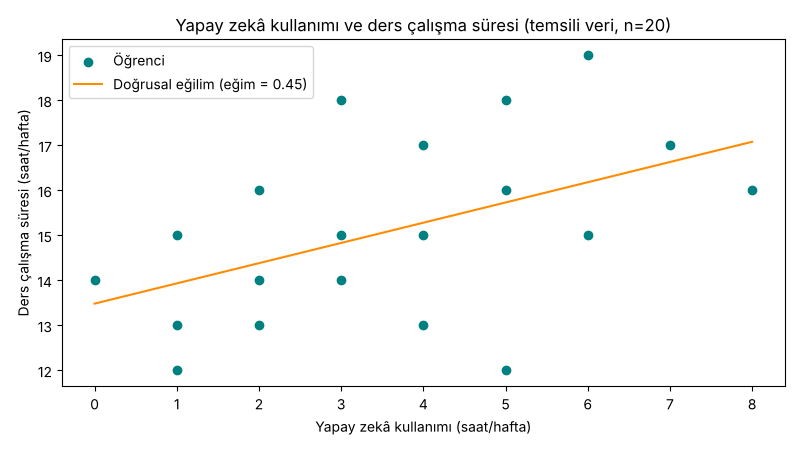

In [3]:
import numpy as np
import matplotlib.pyplot as plt

klasor = Path("sonuc")
klasor.mkdir(exist_ok=True)

x = veri["haftalik_ai_saati"]
y = veri["haftalik_calisma_saati"]
egim, kesisim = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x, y, color="teal", label="Öğrenci")
xs = np.linspace(x.min(), x.max(), 50)
ax.plot(xs, egim * xs + kesisim, color="darkorange", label=f"Doğrusal eğilim (eğim = {egim:.2f})")
ax.set_xlabel("Yapay zekâ kullanımı (saat/hafta)")
ax.set_ylabel("Ders çalışma süresi (saat/hafta)")
ax.set_title("Yapay zekâ kullanımı ve ders çalışma süresi (temsili veri, n=20)")
ax.legend()
fig.tight_layout()
fig.savefig(klasor / "grafik.png", dpi=160)
veri.to_csv(klasor / "kullanilan_veri.csv", index=False)
plt.show()
print(f"Eğim: {egim:.2f} saat/saat, kesişim: {kesisim:.2f} saat")

## E. Akademik yorum
**Veri kaynağı ve değişken:** Temsili 20 öğrencilik veri setinde, haftalık yapay zekâ kullanım süresi (saat) ile haftalık ders çalışma süresi (saat) incelenmiştir. Veri gerçek bir ölçüm değildir.

**Toplam / ortalama ve birimler:** Öğrenciler ortalama haftada 3,6 saat yapay zekâ kullanmakta (toplam 72 saat), ortalama 15,1 saat ders çalışmaktadır (toplam 302 saat).

**Grafikte görülen bulgu:** İki değişken arasında orta düzeyde pozitif bir ilişki görülmektedir (r ≈ 0,49); doğrusal eğilime göre yapay zekâ kullanımı haftada 1 saat arttığında çalışma süresi ortalama 0,45 saat artmaktadır.

**Sınırlılıklar ve ölçemediği şeyler:** Örneklem küçük (n=20) ve temsilidir; yapay zekâ kullanımının *nasıl* olduğu (öğrenme mi, ödev kopyalama mı), çalışmanın verimi ve not başarısı ölçülmemiştir. Aykırı değerler ve ders yükü gibi üçüncü değişkenler kontrol edilmemiştir.

**Ekipçe yapılan işlem:** [yazınız — veri toplama, temizleme, grafik, yorum görev dağılımı]

> Grafikte iki değişken birlikte görünse bile tek başına neden-sonuç kanıtı oluşmaz. Yapay zekâ kullanımı çalışma süresini artırıyor olabileceği gibi, çok çalışan öğrenciler yapay zekâyı daha çok kullanıyor da olabilir.

## F. Teslim kontrolü
- [x] Çalışır `.ipynb` dosyası
- [x] CSV/JSON örneği veya yasal ve erişilebilir veri kaynağı (temsili CSV)
- [x] Birim + veri kaynağı + lisans
- [x] En az 1 açıklamalı grafik
- [x] Toplam ve ortalama hesabı
- [x] 4–5 cümlelik yorum
- [ ] README içinde ekip katkıları
- [ ] GitHub repo bağlantısı
- [x] Gizli/kişisel veri ve anahtar bulunmuyor